In [1]:
from ngsolve import *
import numpy as np
import ngsolve
from ngsolve.webgui import Draw
ngsglobals.msg_level = 1
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from domain_ac import *
from implicit_ac import implicit
from functions_ac import *
#general parameters
sigma = 1 #switching parameter (0 e.g. if f is linear wrt q)
L = 1 #parameter if the functional in the u update is implemented as a simple multiplication

tstart = 0
tend = 10
tsteps = 10 * int(1e3)

t = Parameter(tstart) #time parameter that will be updated
dt = (tend-tstart)/tsteps

k_u = 3 # order of Ufes, Qfes is hard coded as L2 with order 0
maxh = 0.1 # mesh size for domain

In [2]:
# Build domain
dom = domain(maxh = maxh)
mesh, Ufes, Qfes = dom.mesh, dom.Ufes, dom.Qfes
print(Ufes.ndof,Qfes.ndof)

8542 1858


In [ ]:
v_bg  = 1
v_inc1 = 4
v_inc2 = 2
v_side = 3
r1 = IfPos(x + y - 1, 1, 0)
        
r2 = IfPos(x - 2*y + 0.4, 1, 0)*IfPos(x + y - 1, 0, 1)
        
q_exact = (v_bg * (1-r1) * (1-r2)+ 
                  v_inc1 * r1 + 
                  v_inc2 * r2)
#q_exact = 0.5*exp(sin(1*pi*x)*sin(1*pi*y))#(pi-sqrt(x**2+y**2))#cos(x)*cos(y)*cos(x-.6) #exact q
q_norm = norm(q_exact,mesh)
#q_gfq = GridFunction(Qfes)
#q_gfq.Set(q_exact)
#q_exact = CF(q_gfq)
Draw(q_exact,mesh)

u_exact_wot = sin(0.25*pi*(x-2))*sin(0.5*pi*(y-1))#+0.1*sin(pi*x)*sin(pi*y)+0.2*sin(2*pi*x)*sin(pi*x)
#exp(sin(0.5*pi*x)*sin(0.5*pi*y))
Draw(u_exact_wot,mesh)
u_exact = GridFunction(Ufes)#[GridFunction(Ufes) for i in range(tsteps)]

z_min, z_max = 0.2, 1
def set_u(t,counter):
    decay = float((tend-(t.Get()+dt))/(tend-tstart))#np.exp(-t.Get())*t.Get()
    if counter==tsteps-1:
        #save ground truth
        np.save("u_exact.npy", u_exact.vec.FV().NumPy().copy())
        q_exact_gf = GridFunction(Qfes)
        q_exact_gf.Set(q_exact)
        np.save("q_exact.npy", q_exact_gf.vec.FV().NumPy().copy())
    return u_exact_wot*decay+z_min

#save ground truth
t.Set(0)
u_exact_gf_init = GridFunction(Ufes)
u_exact_gf_init.Set(set_u(t,counter = 0))
np.save("u_exact_init.npy", u_exact_gf_init.vec.FV().NumPy().copy())

t.Set(tend)
u_exact_gf = GridFunction(Ufes)
u_exact_gf.Set(set_u(t,counter = tsteps-1))
np.save("u_exact.npy", u_exact_gf.vec.FV().NumPy().copy())

q_exact_gf = GridFunction(Qfes)
q_exact_gf.Set(q_exact)
np.save("q_exact.npy", q_exact_gf.vec.FV().NumPy().copy())
#Set up Gridfunctions, that will updated trough the time steps
gfu, gfq, z, z_old, ut, u_exact_old = GridFunction(Ufes), GridFunction(Qfes), GridFunction(Ufes), GridFunction(Ufes), GridFunction(Ufes), GridFunction(Ufes)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

In [ ]:
q_init = q_exact
umin, umax, qmin, qmax = 0, 3,0,3
def real_root(x, n):
    return np.sign(x) * (abs(x))**(1/n)
def C(gfq,q_exact = q_exact, q_init = q_init):
    return 2+((z_max/z_min)*norm(gfq,mesh)**(2/3)+norm(q_exact,mesh)**(2/3)+real_root(Integrate(q_init**3,mesh),3)**(2/3))**2
def absolut (gf):
    return sqrt(gf*gf)

0.0/10

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

0.004/10

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

... (39 outputs left out)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

9.998999999999898/10

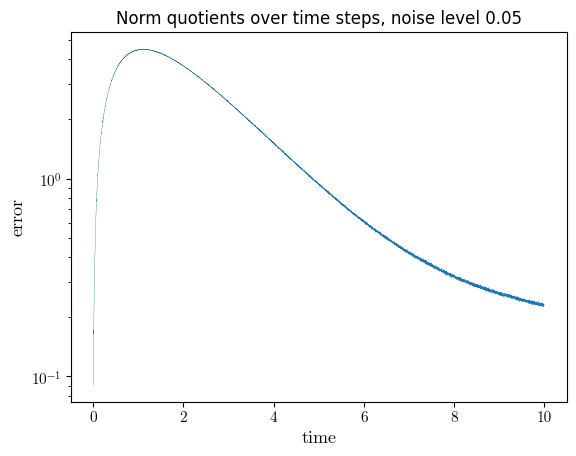

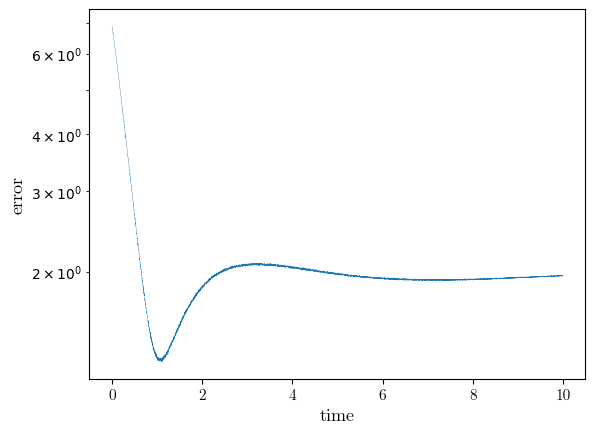

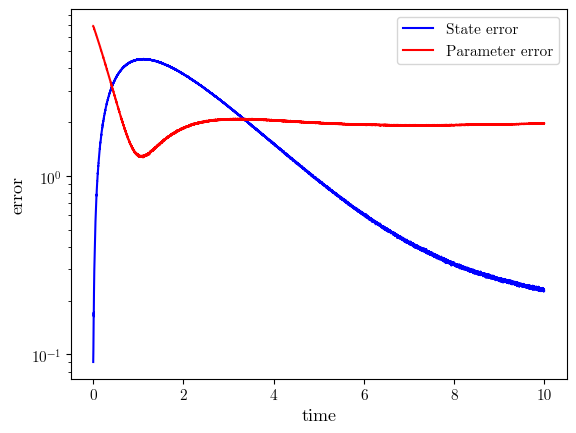

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

In [ ]:
X = FESpace([Ufes,Qfes])
u, q = X.TrialFunction()
v, s = X.TestFunction()
gf = GridFunction(X)
aux = GridFunction(X) #we later write the update to this function, and then add it to gf
n = specialcf.normal(mesh.dim)
for noise_level in [0,0.1,0.2,0.05]:
    # Initial u and q
    t.Set(0)
    gfu.Set(u_exact)
    gfq.Set(0)#cos(x)*cos(y))
    gf = GridFunction(X)
    aux.vec.data[:] = 0
    #compute initial error
    error_u = []#norm(gfu-u_exact, mesh)]
    error_q = []#error_q = [norm(gfq-q_exact, mesh)]
    saved_gfu = []
    saved_gfu.append(gfu.vec.FV().NumPy().copy())
    saved_gfq = []
    saved_gfq.append(gfq.vec.FV().NumPy().copy())
    counter = 0
    gf.components[0].Set(z,definedon=mesh.Boundaries("circle"), )
    series_gfq, series_gfu = [],[]
    series_gfu.append(gfu.vec.FV().NumPy().copy())
    series_gfq.append(gfq.vec.FV().NumPy().copy())
    norm_old = 1
    norm_list = []
    while t < tend - dt:
        norm_old = norm_new if counter>0 else None
        print("\r",t.Get(),"/",tend,sep="",end="")
        # Get updated data z and g
        ut = GridFunction(Ufes) #derivate in time
        u_exact_old.vec.data = u_exact.vec.Copy()
        u_exact.Set(set_u(t,counter))
        ut.vec.data = u_exact.vec.Copy()
        ut.vec.data -= u_exact_old.vec.Copy()
        ut.vec.data /= dt
        z, noise = add_noise(u_exact,noise_level,Ufes,mesh,20)
        zt = GridFunction(Ufes) #derivate in time
        zt.vec.data = z.vec.Copy()
        zt.vec.data -= z_old.vec.Copy()#u_exact_dt[int(t.Get()/dt)]#
        zt.vec.data /= dt
        z_old.vec.data = z.vec.Copy()
        #g = #zt + f(q_exact,z) #scrap this and do it below explicitly
        #we do g in the weak form below, therefore terms including q_exact occur
        
        a = BilinearForm(X)
        res = LinearForm(X)
        
        #c eq. 
        a += q * s * dx
        a += sigma * dt * q * z * z * z * s * dx
        a += sigma * dt * (absolut(gfq)**(2/3)*q*z + q*z) * s * dx
        
        res += sigma * dt * ut * s * dx #instead of g
        res += sigma * dt * absolut(q_exact)**(2/3) * q_exact * u_exact * s * dx #instead of g
        if noise_level>0: res += sigma * dt * Grad(u_exact) * Grad(s) * dx #instead of g #cancels without noise
        if noise_level>0: res += -sigma * dt * Grad(u_exact) * n * s * ds #instead of g #cancels without noise
        res += sigma * dt  * q_exact * z * s * dx #instead of g
        res += dt * (1+0*(5/3)*absolut(gfq)**(2/3)) * (z_old)*(gfu-z_old) * s * dx #-z
        res += -sigma * dt * (zt + absolut(gfq)**(2/3) * gfq * z + gfq * z * z * z) * s * dx
        if noise_level>0: res += -sigma * dt * Grad(z) * Grad(s) * dx #cancels without noise
        if noise_level>0: res += sigma * dt * Grad(z) * n * s * ds #cancels without noise
        
        # u eq.
        a += u * v * dx 
        a += dt * C(gfq) * Grad(u) * Grad(v) * dx
        a += dt * q * z * z * z * v * dx
        a += dt * absolut(gfq)**(2/3) * q * z * v * dx

        res += dt * absolut(q_exact)**(2/3) * q_exact * u_exact * v * dx#instead of g
        res += dt * zt * v * dx #instead of g
        if noise_level>0: res += dt * Grad(u_exact) * Grad(v) * dx #instead of g #cancels without noise
        if noise_level>0:res += -dt * Grad(u_exact) * n * v * ds #instead of g #cancels
        res += dt  * q_exact * u_exact * v * dx #instead of g
        res += -dt * absolut(gfq)**(2/3)*gfq*z * v * dx
        res += -dt * gfq * z * z * z * v * dx
        if noise_level>0: res += -dt * Grad(z) * Grad(v) * dx # cancels without noise
        if noise_level>0: res += dt * Grad(z) * n * v * ds # cancels
        res += -dt * C(gfq) * Grad(gfu) * Grad(v) * dx
        res += dt * C(gfq) * Grad(z) * Grad(v) * dx

        a.Assemble()
        res.Assemble()  

        c = Preconditioner(a,"local")   #<-Jacobi preconditioner
        c.Update()
        solvers.BVP(bf=a, lf=res, gf=aux, pre=c, print=False)
        gf.vec.data += aux.vec.data
        
        gfu.Set(gf.components[0])
        error_q.append(norm(gfq-q_exact,mesh))
        if counter%100==0: saved_gfq.append(gfq.vec.FV().NumPy().copy())
        gfq.Set(gf.components[1])         
        error_u.append(norm(gfu-u_exact,mesh))
        norm_new = norm(gfu-z,mesh)
        norm_quot = norm_new/norm_old if norm_old is not None else None
        if counter%100==0: saved_gfu.append(gfu.vec.FV().NumPy().copy())
        #if counter%20==0: 
        #    norm_list.append(norm_quot)
        """
        if norm_new < norm(noise,mesh) and counter>100:
            print("stopping criterion reached at time ", t.Get())
            series_gfu.append(gfu.vec.FV().NumPy().copy())
            series_gfq.append(gfq.vec.FV().NumPy().copy())
            break
        """
        t.Set(t.Get()+ dt)    # Update time
        counter += 1
        #if norm_quot is not None and norm_quot > 1.1:
        #    break
        if counter in [1,5,25,50,75,100,200, 500,1500,2500,5000, tsteps-2]:
            Draw(gfu)#, min = umin, max = umax)
            Draw(z)
            series_gfu.append(gfu.vec.FV().NumPy().copy())
            Draw(gfq)#, min = qmin, max = qmax)
            series_gfq.append(gfq.vec.FV().NumPy().copy())
    #print(error_u)
    #print(error_q)
    #plt.plot(np.arange(len(norm_list)), norm_list)
    np.save("norm_quot_list_"+str(noise_level)+".npy", np.array(norm_list))
    plt.title("Norm quotients over time steps, noise level "+str(noise_level))
    plot_error(tstart,tend,tsteps,noise_level,error_u,error_q)
    draw_gridfuncs (tsteps,u_exact,q_exact,gfu,gfq,mesh)
    save (mesh,noise_level,series_gfu,series_gfq)

In [6]:
Draw(gfu, settings={"Objects": {"Wireframe": False}}) #
Draw(gfq, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

BaseWebGuiScene

In [7]:
Draw(gfu-u_exact,mesh, settings={"Objects": {"Wireframe": False}})
Draw(gfq-q_exact,mesh, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fal…

BaseWebGuiScene

In [8]:
#print(error_q)

In [9]:
#print(error_u)

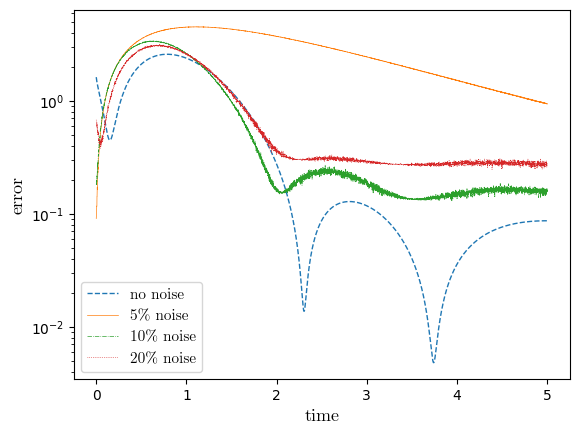

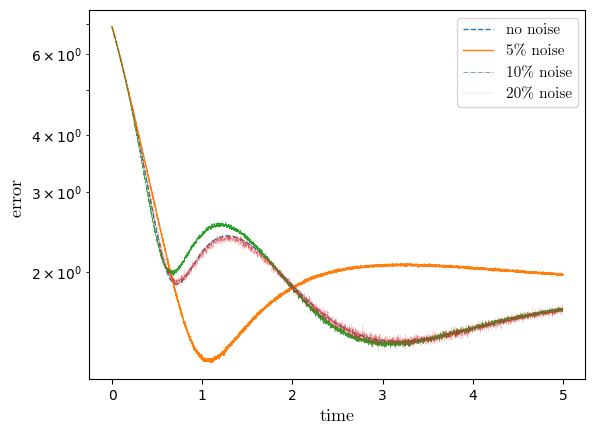

In [10]:
error_u_0 = np.load("error_u_0.npy")
error_q_0 = np.load("error_q_0.npy")
error_u_005 = np.load("error_u_0.05.npy")
error_q_005 = np.load("error_q_0.05.npy")
error_u_01 = np.load("error_u_0.1.npy")
error_q_01 = np.load("error_q_0.1.npy")
error_u_02 = np.load("error_u_0.2.npy")
error_q_02 = np.load("error_q_0.2.npy")

#general font prep
font_path = "cmunrm.ttf"
prop = fm.FontProperties(fname=font_path, size=15)
prop13 = fm.FontProperties(fname=font_path, size=13)
prop11 = fm.FontProperties(fname=font_path, size=11)

font_path = "cmunrm.ttf"
prop = fm.FontProperties(fname=font_path, size=15)
prop13 = fm.FontProperties(fname=font_path, size=13)
prop11 = fm.FontProperties(fname=font_path, size=11)

plt.plot(np.linspace(0,5,len(error_u_0[:5000])), error_u_0[:5000], label="no noise", linewidth=1, linestyle='dashed')
plt.plot(np.linspace(0,5,len(error_u_005[:5000])), error_u_005[:5000], label="5% noise", linewidth=.5, linestyle='solid')
plt.plot(np.linspace(0,5,len(error_u_01[:5000])), error_u_01[:5000], label="10% noise", linewidth=.5, linestyle='dashdot')
plt.plot(np.linspace(0,5,len(error_u_02[:5000])), error_u_02[:5000], label="20% noise", linewidth=.5, linestyle='dotted')
plt.yscale("log")
#plt.title("Error in u over iterations", fontproperties=prop)
plt.xlabel("time", fontproperties=prop13)
plt.ylabel("error", fontproperties=prop13)
plt.legend(prop=prop11)
plt.savefig("all State errors ac.jpg", dpi=300)

plt.show()
plt.plot(np.linspace(0,5,len(error_q_0[:5000])), error_q_0[:5000], label="no noise",linewidth=1, linestyle='dashed')
plt.plot(np.linspace(0,5,len(error_q_005[:5000])), error_q_005[:5000], label="5% noise", linewidth=1, linestyle='solid')
plt.plot(np.linspace(0,5,len(error_q_01[:5000])), error_q_01[:5000], label="10% noise", linewidth=0.5, linestyle='dashdot')
plt.plot(np.linspace(0,5,len(error_q_02[:5000])), error_q_02[:5000], label="20% noise", linewidth= 0.2, linestyle='dotted')
plt.yscale("log")
plt.xlabel("time", fontproperties=prop13)
plt.ylabel("error ", fontproperties=prop13)
plt.legend(prop=prop11)
plt.savefig("all Parameter errors ac.jpg", dpi=300)
plt.show()  
